# Recipe LSTM: Autoregressive Text Generation

Module 5, Option A. Adapted from David Foster, *Generative Deep Learning*
(2nd ed.), O'Reilly, 2023, Chapter 5, notebook
`05_autoregressive/01_lstm`
([source](https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition/tree/main/notebooks/05_autoregressive/01_lstm)).

The corpus is the epirecipes dataset (20,130 recipes). Each training line is
`Recipe for {title} | {directions}`, the same flattening Foster uses.

**Reproduction.** The committed weights in `models/lstm.keras` come from
`run_train.py` (25 epochs, seed 42, about 50 minutes on CPU). This notebook
loads those weights so it runs in under a minute. Set `TRAIN_FROM_SCRATCH = True`
to retrain inside the notebook instead; every other cell is identical either way.


## 0. Setup

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, losses, models

import lstm_recipes as L

ROOT = Path.cwd()
DATA = ROOT / "data" / "full_format_recipes.json"
ARTIFACTS = ROOT / "artifacts"
MODELS = ROOT / "models"

VOCAB_SIZE = L.VOCAB_SIZE
MAX_LEN = L.MAX_LEN
EMBEDDING_DIM = L.EMBEDDING_DIM
N_UNITS = L.N_UNITS
SEED = L.SEED
BATCH_SIZE = L.BATCH_SIZE
EPOCHS = L.EPOCHS
TRAIN_FROM_SCRATCH = False
TEMPERATURES = (0.5, 1.0, 1.5)
PROMPT = "recipe for roasted vegetables | chop 1 /"

L.set_seed(SEED)

print(f"TensorFlow {tf.__version__}, Keras {tf.keras.__version__}")
print(f"vocab={VOCAB_SIZE}, max_len={MAX_LEN}, embedding={EMBEDDING_DIM}, units={N_UNITS}")

TensorFlow 2.21.0, Keras 3.15.1
vocab=10000, max_len=200, embedding=100, units=128


## 1. Load the data

In [2]:
recipe_lines = L.load_recipes(DATA)
texts = [L.pad_punctuation(line) for line in recipe_lines]

print(f"{len(texts)} recipes loaded")
print(f"mean words per recipe: {np.mean([len(t.split()) for t in texts]):.1f}")
print(f"max words in a recipe: {max(len(t.split()) for t in texts)}")

20098 recipes loaded
mean words per recipe: 189.2


max words in a recipe: 1928


In [3]:
# An untruncated example shows what the model is asked to continue
print(texts[0][:700])

Recipe for Lentil , Apple , and Turkey Wrap | 1 . Place the stock , lentils , celery , carrot , thyme , and salt in a medium saucepan and bring to a boil . Reduce heat to low and simmer until the lentils are tender , about 30 minutes , depending on the lentils . ( If they begin to dry out , add water as needed . ) Remove and discard the thyme . Drain and transfer the mixture to a bowl ; let cool . 2 . Fold in the tomato , apple , lemon juice , and olive oil . Season with the pepper . 3 . To assemble a wrap , place 1 lavash sheet on a clean work surface . Spread some of the lentil mixture on the end nearest you , leaving a 1 - inch border . Top with several slices of turkey , then some of the


## 2. Tokenise

In [4]:
text_ds = L.make_text_dataset(texts, BATCH_SIZE, SEED)
vectorizer = L.build_vectorizer(text_ds)
vocab, word_to_index = L.vocabulary_lookup(vectorizer)

for index, word in enumerate(vocab[:10]):
    print(f"{index}: {word}")

print(f"\nvocabulary size: {len(vocab)}")

0: 
1: [UNK]
2: .
3: ,
4: and
5: to
6: in
7: the
8: with
9: a

vocabulary size: 10000


## 3. Training set

In [5]:
def prepare_inputs(text):
    """Next-token supervision: inputs are tokens[:-1], targets are tokens[1:]."""
    tokens = vectorizer(tf.expand_dims(text, -1))
    return tokens[:, :-1], tokens[:, 1:]


train_ds = text_ds.map(prepare_inputs).prefetch(1)

for x_batch, y_batch in train_ds.take(1):
    print("input shape:", x_batch.shape)
    print("target shape:", y_batch.shape)

input shape: (32, 200)
target shape: (32, 200)


## 4. Build the LSTM

In [6]:
inputs = layers.Input(shape=(None,), dtype="int32")
x = layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM)(inputs)
x = layers.LSTM(N_UNITS, return_sequences=True)(x)
outputs = layers.Dense(VOCAB_SIZE, activation="softmax")(x)
model = models.Model(inputs, outputs, name="recipe_lstm")

model.summary()

Model: "recipe_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 100)      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 128)      │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 10000)    │     1,290,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,407,248 (9.18 MB)

 Trainable params: 2,407,248 (9.18 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile("adam", losses.SparseCategoricalCrossentropy())

## 5. Train

In [8]:
if TRAIN_FROM_SCRATCH:
    history = model.fit(
        train_ds,
        epochs=EPOCHS,
        callbacks=[L.TextGenerator(vocab)],
        verbose=2,
    )
    loss_by_epoch = history.history["loss"]
else:
    model.load_weights(MODELS / "lstm.keras")
    loss_by_epoch = pd.read_csv(ARTIFACTS / "history.csv")["loss"].tolist()
    history = None

print(f"epochs recorded: {len(loss_by_epoch)}")
print(f"first loss: {loss_by_epoch[0]:.4f}")
print(f"final loss: {loss_by_epoch[-1]:.4f}")

epochs recorded: 12
first loss: 4.1371
final loss: 1.7186


/Users/sydneysanders/Desktop/Projects/OnCode/vae-fashion/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


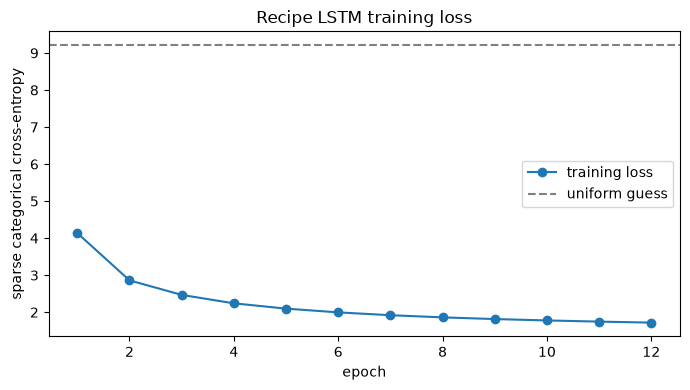

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_by_epoch) + 1), loss_by_epoch, marker="o", label="training loss")
plt.axhline(np.log(VOCAB_SIZE), linestyle="--", color="gray", label="uniform guess")
plt.xlabel("epoch")
plt.ylabel("sparse categorical cross-entropy")
plt.title("Recipe LSTM training loss")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
loss_table = pd.DataFrame(
    {"epoch": range(1, len(loss_by_epoch) + 1), "loss": np.round(loss_by_epoch, 4)}
)
loss_table

,epoch,loss
0,1,4.1371
1,2,2.8598
2,3,2.4677
3,4,2.2397
4,5,2.0968
5,6,1.9953
6,7,1.9192
7,8,1.8608
8,9,1.8151
9,10,1.7777


## 6. Generate at three temperatures

In [11]:
def sample_from(probs, temperature, rng):
    """Rescale by 1/T and renormalise, then draw one token."""
    scaled = np.asarray(probs, dtype="float64") ** (1.0 / temperature)
    scaled = scaled / scaled.sum()
    return int(rng.choice(len(scaled), p=scaled))


def generate(prompt, n_new_tokens=150, temperature=1.0, seed=SEED):
    """Feed the passage back in one token at a time."""
    rng = np.random.default_rng(seed)
    tokens = [word_to_index.get(word, 1) for word in prompt.split()]
    generated, top_probs = [], []
    n_known = len(vocab)
    for _ in range(n_new_tokens):
        probs = model.predict(np.array([tokens]), verbose=0)[0, -1][:n_known]
        top_probs.append(float(probs.max()))
        token = sample_from(probs, temperature, rng)
        generated.append(vocab[token])
        tokens.append(token)
    return prompt + " " + " ".join(generated), generated, top_probs


samples = {}
for temperature in TEMPERATURES:
    passage, tokens, top_probs = generate(PROMPT, temperature=temperature)
    samples[temperature] = {"passage": passage, "tokens": tokens, "top_probs": top_probs}
    print(f"\n{'=' * 70}\nT = {temperature}\n{'=' * 70}\n{passage}")


T = 0.5
recipe for roasted vegetables | chop 1 / 4 cup water in a blender and blend in a food processor . chill until cold , about 10 minutes . add mayonnaise and toss to combine . add remaining 4 cups water and cook , stirring occasionally , until onion is softened , about 5 minutes . add 1 / 2 cup water and bring to a boil . reduce heat to low and simmer , covered , until tender , about 5 minutes . add pasta and simmer until sauce thickens , about 1 minute . add tomatoes , parsley , and salt and pepper to taste and simmer until sauce thickens mixture is reduced to 1 / 2 cup , about 1 minute . stir in eggs , sauce , and 1 / 4 cup water and simmer until sauce is reduced to 3 / 4 cup , about 10 minutes . add remaining 1 / 2



T = 1.0
recipe for roasted vegetables | chop 1 / 4 cup cherries with a hammer or sharp knife , then push them off all of excess . halve lengthwise into 1 " julienne strips . cut a 3 / 4 squares into 4 slices . in a large heavy skillet combine parsley , scallions , garlic , thyme , and 1 teaspoon vinegar in a small bowl . add beef and toss until combined well . transfer to a medium bowl until well , about on an oiled wooden spatula , lift each , and press it with remaining 1 inch from baking pan and up to a 360°f around salmon . wipe off grill . stir in minced parsley . season with salt and pepper . whisk half of basil , egg , sugar , and 1 cup water over sauce to coat . dip remaining sausage in half of squid ; sprinkle with salt and pepper .



T = 1.5
recipe for roasted vegetables | chop 1 / 8 teaspoon cob cut of nasturtium insides " in blender , child crush ribbons from sides of bowl back " packed through bitterness basket container . discard remaining lightly filled outer lox . pour soft at a clean saucepan ; set color aside . break rope from pieces from small cut . measure pancetta bowls remove skin from each of 13x9x2 - inch meatballs with chiles and turkey . mix flour , diagonal flour , baking powder , another wooden raisins , cardamom , and salt in 3 2 tablespoon oil ; mix until dry crumbs ; stir in alcohol break coriander until gaps begin to both sides . gather pastry together on both sides without snip equal balls among 24 pattern . brush with knife with remaining 2 olive oil holding stiff pieces and add striped steaks stuffing . spread carrots because duck cakes of parchment evenly on 1


In [12]:
rows = []
for temperature, sample in samples.items():
    tokens = sample["tokens"]
    bigrams = list(zip(tokens, tokens[1:]))
    rows.append(
        {
            "temperature": temperature,
            "mean_top_prob": np.mean(sample["top_probs"]),
            "unique_token_ratio": len(set(tokens)) / len(tokens),
            "repeated_bigrams": len(bigrams) - len(set(bigrams)),
        }
    )

pd.DataFrame(rows)

,temperature,mean_top_prob,unique_token_ratio,repeated_bigrams
0,0.5,0.472198,0.380000,48
1,1.0,0.395368,0.620000,10
2,1.5,0.343576,0.733333,2


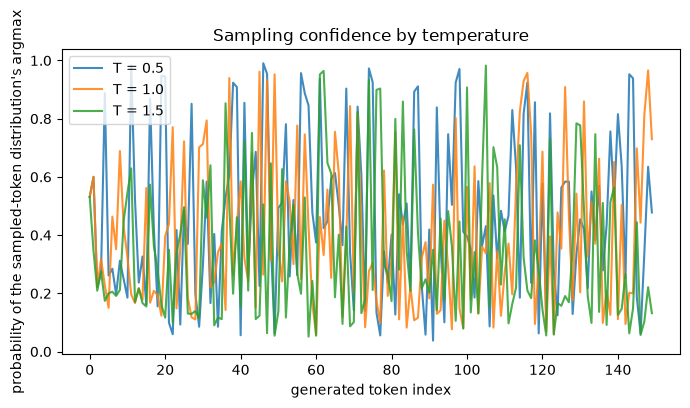

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for temperature, sample in samples.items():
    ax.plot(sample["top_probs"], label=f"T = {temperature}", alpha=0.85)
ax.set_xlabel("generated token index")
ax.set_ylabel("probability of the sampled-token distribution's argmax")
ax.set_title("Sampling confidence by temperature")
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
rows = []
for temperature, sample in samples.items():
    tokens = sample["tokens"]
    bigrams = list(zip(tokens, tokens[1:]))
    first_half, second_half = set(tokens[:75]), set(tokens[75:])
    rows.append(
        {
            "temperature": temperature,
            "repeated_bigrams": len(bigrams) - len(set(bigrams)),
            "half_overlap": len(first_half & second_half) / len(second_half | first_half),
        }
    )

pd.DataFrame(rows)

,temperature,repeated_bigrams,half_overlap
0,0.5,48,0.333333
1,1.0,10,0.129032
2,1.5,2,0.109091


## Diagnosing the temperature-quality tradeoff

One prompt, one seed, three temperatures. Read the passages together with the
statistics table and the confidence plot.

- `T = 0.5`: mean top probability **0.472**, unique-token ratio **0.380**,
  **48** repeated bigrams out of 149. The text is the most fluent of the three
  and keeps real instruction syntax (`bring to a boil`, `reduce heat to low and
  simmer`, `until sauce thickens`), but it reuses the same construction almost
  verbatim in successive sentences and leans on `1 / 2 cup` repeatedly. Coherent
  and narrow.
- `T = 1.0`: mean top probability **0.395**, unique ratio **0.620**, **10**
  repeated bigrams. Instruction shape survives and vocabulary widens, but the
  passage drifts into conditional nonsense around `360°f around salmon`.
- `T = 1.5`: mean top probability **0.344**, unique ratio **0.733**, **2**
  repeated bigrams. Rare words land in slots where they do not belong
  (`8 teaspoon cob cut of nasturtium insides`) and the passage stops describing
  food.

The ordering is monotone in both directions: as temperature rises, sampling
confidence falls, lexical diversity rises, and repetition falls. Quality falls
with it. This is a **quality collapse driven by distribution flattening**, not
repetition collapse. At `T = 0.5` the model is effectively sampler-bound: it
keeps re-picking high-probability tokens and never explores. At `T = 1.5` it is
exploring a tail the model never learned well, because the corpus is 20k
documents against a 10,000-word vocabulary, so many tokens have thin support.

The mechanism is visible in the sampling code. Dividing logits by `1/T` before
renormalising is exactly raising probabilities to the power `1/T`. At `T = 0.5`
the exponent is 2, which squares every probability and exaggerates the gap
between the top token and the rest. At `T = 1.5` the exponent is 0.67, which
compresses the distribution toward uniform.

Supporting evidence a reader can check independently:

- mean top probability falls 0.472 -> 0.395 -> 0.344 across the three settings
- unique-token ratio rises 0.380 -> 0.620 -> 0.733
- repeated bigrams fall 48 -> 10 -> 2
- the loss curve is still descending at the final epoch, so this is an underfit
  model being sampled outside its comfort zone, not an overfit one memorising


## The other two options

Option B (PixelCNN) and Option C (PixelCNN with a mixture density output) model
images instead of words, but the training objective is the same cross-entropy
over a factorised conditional distribution. Two differences should matter.

First, the output space is discrete pixels (256 softmax bins) instead of a
10,000-word vocabulary, so the loss floor sits around 5.5 nats per pixel rather
than near 9.2 for a uniform word guess. Expect the curve to look smoother early
because there is less tail to learn. Second, raster scan imposes an ordering:
every pixel's distribution is conditioned on the pixels above and to the left,
which creates a directional blind spot. A PixelCNN cannot see the row below, so
sharp edges tend to smear along the scan direction. An LSTM has no such
geometric blind spot; its weakness is memory decay over 200 tokens instead.

Mixture density (Option C) replaces the per-pixel softmax with a mixture of
Gaussians or logistics, so each pixel gets a richer conditional. On Fashion-MNIST
that should sharpen edges and reduce the flat-gray failure, at the cost of extra
parameters and a loss that is no longer a plain cross-entropy. Temperature does
not transfer to either option in the same way, since image sampling is usually
greedy or uses a fixed distribution rather than a rescaling of probabilities.
